# Corrida 2: evaluación con tres ajustes

En la corrida 1 (`notebooks/evaluacion_colab.ipynb`) aparecieron tres problemas que dependen de la configuración:

1. Con una pregunta por variable, la respuesta de HbA1c repetía la pregunta y se cortaba en los 20 tokens antes del número.
2. Con el prompt original, el modelo respondió «No registrado» 22 veces cuando la historia dice que el paciente no tiene la condición.
3. Con JSON, 6 de las 15 historias entraron en un ciclo («Sí, no. Sí, no…») hasta los 200 tokens.

Esta corrida prueba un ajuste para cada problema, uno encima del otro, para ver cuánto aporta cada uno (ablación). **Los ajustes se decidieron mirando estos mismos 15 casos**, así que las mejoras pueden ser optimistas.

Antes de empezar, en **Entorno de ejecución → Cambiar tipo de entorno de ejecución**, elige **T4 GPU**. Para clonar el repo privado hace falta el secret `GITHUB_TOKEN` (ver `notebooks/despliegue_colab.ipynb`, celda 2).

Al terminar, descarga el notebook con sus salidas (**Archivo → Descargar → .ipynb**) para guardarlo en el repo. Descarga también los archivos de la carpeta `resultados/`.

## 1. Preparar el entorno

In [1]:
# Sirve en Colab y en una copia local del repo
import os
import subprocess
import sys

REPO_URL = "https://github.com/joan999/aya101_historias_clinicas.git"
RAMA = "main"   # rama que se clona
EN_COLAB = "google.colab" in sys.modules


def token_github():
    """Lee el token de los Secrets de Colab. Si no está, devuelve None."""
    try:
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception as error:
        print("Sin token de GitHub:", type(error).__name__)
        return None


def git(*args, token=None, cwd=None):
    """Corre git y tapa el token en lo que imprime."""
    resultado = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True,
                               env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    texto = (resultado.stdout + resultado.stderr).strip()
    if token:
        texto = texto.replace(token, "***")
    if texto:
        print(texto)
    if resultado.returncode != 0:
        raise RuntimeError("git falló: revisa el secret GITHUB_TOKEN y que el token tenga acceso al repo")


if EN_COLAB:
    token = token_github()
    url = REPO_URL.replace("https://", f"https://x-access-token:{token}@") if token else REPO_URL
    carpeta = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if os.path.exists(carpeta):
        git("pull", "-q", url, RAMA, token=token, cwd=carpeta)
    else:
        git("clone", "-q", "--branch", RAMA, url, carpeta, token=token)
        git("remote", "set-url", "origin", REPO_URL, cwd=carpeta)
    os.chdir(carpeta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.24.0",
                    "accelerate==1.16.0", "bitsandbytes==0.50.2", "pymupdf==2.1"], check=True)
elif not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")   # fuera de Colab se usa la carpeta del repo
sys.path.insert(0, os.getcwd())
print("Carpeta del proyecto:", os.getcwd())

Carpeta del proyecto: /content/aya101_historias_clinicas


## 2. Cargar Aya-101

In [2]:
import time

import torch

from src.config import MODELO_ID
from src.modelo import cargar_modelo

inicio = time.time()
tokenizador, modelo = cargar_modelo(MODELO_ID)
print(f"Modelo: {MODELO_ID} | descarga y carga: {time.time() - inicio:.0f} s")
if torch.cuda.is_available():
    usada = torch.cuda.memory_allocated()
    total = torch.cuda.get_device_properties(0).total_memory
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM del modelo cargado: {usada / 1e9:.2f} GB ({usada / 1024**3:.2f} GiB) de {total / 1e9:.1f} GB")

config.json:   0%|          | 0.00/836 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/833 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors.index.json: reconstructing file:   0%|          |  0.00B / 50.6kB            

model.safetensors.index.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Modelo: CohereLabs/aya-101 | descarga y carga: 1756 s
GPU: Tesla T4
VRAM del modelo cargado: 13.11 GB (12.21 GiB) de 15.6 GB


## 3. Configuraciones

- **Por variable · 40 tokens**: igual que la corrida 1, con el límite de la respuesta en 40 tokens en lugar de 20.
- **Por variable · 40 tokens · prompt Sí/No**: además, las 4 preguntas Sí/No usan esta instrucción: «Responde Sí si la historia lo afirma y No si la historia lo niega o dice lo contrario. Si la historia no dice nada al respecto, responde: No registrado.» Las 6 numéricas no cambian.
- **JSON · sin ciclos**: igual que la corrida 1, pero el decoder no puede repetir un grupo de 10 tokens (`no_repeat_ngram_size=10`). Sigue siendo greedy. 10 es el menor valor que no bloquea ninguna respuesta correcta de las 15 historias.

In [3]:
import json
from pathlib import Path

import pandas as pd

from src.config import MAX_TOKENS_JSON, TIPOS, VARIABLES
from src.inferencia import inferir
from src.metricas import clasificar, es_json_valido
from src.posproceso import leer_json, normalizar
from src.prompts import prompt_json, prompt_por_variable

CONFIGURACIONES = [
    {"nombre": "Por variable · 40 tokens", "estrategia": "por_variable", "max_tokens": 40, "variante": "original", "no_repeat": None},
    {"nombre": "Por variable · 40 tokens · prompt Sí/No", "estrategia": "por_variable", "max_tokens": 40, "variante": "negacion", "no_repeat": None},
    {"nombre": "JSON · sin ciclos", "estrategia": "json", "max_tokens": MAX_TOKENS_JSON, "variante": None, "no_repeat": 10},
]
display(pd.DataFrame(CONFIGURACIONES).set_index("nombre"))

,estrategia,max_tokens,variante,no_repeat
nombre,,,,
Por variable · 40 tokens,por_variable,40,original,NaN
Por variable · 40 tokens · prompt Sí/No,por_variable,40,negacion,NaN
JSON · sin ciclos,json,200,None,10.0


## 4. Correr los 15 casos

Después de cada historia se guardan los CSV y se libera la caché de la GPU, para no perder lo avanzado si la memoria no alcanza. La columna `n_tokens` dice cuántos tokens generó el modelo; si llega al límite, la respuesta se cortó.

In [4]:
esperados = json.loads(Path("ejemplos_hc/esperados.json").read_text(encoding="utf-8"))
filas, corridas = [], []
Path("resultados").mkdir(exist_ok=True)
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

for caso, valores in esperados.items():
    historia = Path("ejemplos_hc", caso).read_text(encoding="utf-8").strip()
    for cfg in CONFIGURACIONES:
        inicio = time.time()
        if cfg["estrategia"] == "por_variable":
            prompts = [prompt_por_variable(historia, pregunta, tipo, cfg["variante"]) for _, tipo, pregunta in VARIABLES]
            salida = inferir(tokenizador, modelo, prompts, historia, cfg["max_tokens"], cfg["no_repeat"])
            segundos = time.time() - inicio
            for (clave, tipo, _), res in zip(VARIABLES, salida):
                valor = normalizar(res["texto"], tipo)
                filas.append({"caso": caso, "estrategia": cfg["nombre"], "variable": clave, "tipo": tipo, "respuesta": res["texto"],
                              "n_tokens": res["n_tokens"], "valor": valor, "esperado": valores[clave],
                              "resultado": clasificar(valor, valores[clave])})
            al_limite = sum(res["n_tokens"] >= cfg["max_tokens"] for res in salida)
            corridas.append({"caso": caso, "estrategia": cfg["nombre"], "segundos": segundos, "json_valido": None, "al_limite": al_limite})
        else:
            res = inferir(tokenizador, modelo, [prompt_json(historia)], historia, cfg["max_tokens"], cfg["no_repeat"])[0]
            segundos = time.time() - inicio
            leidos = leer_json(res["texto"])
            for clave, tipo in TIPOS.items():
                filas.append({"caso": caso, "estrategia": cfg["nombre"], "variable": clave, "tipo": tipo, "respuesta": res["texto"],
                              "n_tokens": res["n_tokens"], "valor": leidos[clave], "esperado": valores[clave],
                              "resultado": clasificar(leidos[clave], valores[clave])})
            corridas.append({"caso": caso, "estrategia": cfg["nombre"], "segundos": segundos,
                             "json_valido": es_json_valido(res["texto"]), "al_limite": int(res["n_tokens"] >= cfg["max_tokens"])})
    pd.DataFrame(filas).to_csv("resultados/corrida2_detalle.csv", index=False)
    pd.DataFrame(corridas).to_csv("resultados/corrida2_tiempos.csv", index=False)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(caso, "listo")

resultados = pd.DataFrame(filas)
resultados["correcto"] = resultados["resultado"] == "correcto"
corridas = pd.DataFrame(corridas)
print("Guardado en resultados/:", len(resultados), "casillas y", len(corridas), "corridas")

caso_1.txt listo
caso_2.txt listo
caso_3.txt listo
caso_4.txt listo
caso_5.txt listo
caso_6.txt listo
caso_7.txt listo
caso_8.txt listo
caso_9.txt listo
caso_10.txt listo
caso_11.txt listo
caso_12.txt listo
caso_13.txt listo
caso_14.txt listo
caso_15.txt listo
Guardado en resultados/: 450 casillas y 45 corridas


## 5. Resultados por configuración

Las mismas métricas de la corrida 1: exactitud con intervalo de Wilson, y precisión, recall y F1 con intervalo bootstrap por historias. `al límite` cuenta las respuestas que se cortaron por el número de tokens.

In [5]:
from scripts.recalcular_metricas import resumen

tabla2 = resumen(filas).set_index("estrategia")
extra = corridas.groupby("estrategia", sort=False).agg(al_limite=("al_limite", "sum"), segundos_medios=("segundos", "mean"))
tabla2 = tabla2.join(extra)
validos = corridas[corridas["estrategia"].str.contains("JSON")]
tabla2.loc[validos["estrategia"].iloc[0], "json_valido"] = f"{int(validos['json_valido'].sum())} de {len(validos)}"
tabla2.to_csv("resultados/corrida2_resumen.csv")
display(tabla2)

,aciertos,total,exactitud,IC 95 % exactitud,VP,FP,FN,precisión,recall,F1,IC 95 % F1,n_correcto,n_valor distinto,n_omitido,n_inventado,al_limite,segundos_medios,json_valido
estrategia,,,,,,,,,,,,,,,,,,
Por variable · 40 tokens,114,150,0.76,0.686 – 0.821,108,14,36,0.885,0.750,0.812,0.762 – 0.856,114,14,22,0,0,24.506870,NaN
Por variable · 40 tokens · prompt Sí/No,114,150,0.76,0.686 – 0.821,108,16,36,0.871,0.750,0.806,0.749 – 0.856,114,16,20,0,0,25.271156,NaN
JSON · sin ciclos,81,150,0.54,0.460 – 0.618,77,4,67,0.951,0.535,0.684,0.463 – 0.846,81,2,65,2,0,11.314755,0 de 15


## 6. Ablación: corrida 1 frente a corrida 2

La corrida 1 se toma de `doc/metricas/recalculo_corrida1/`, con el lector corregido. En la corrida 1 no se guardó `n_tokens`: las respuestas al límite se estiman volviendo a tokenizar el texto generado.

In [6]:
tabla1 = pd.read_csv("doc/metricas/recalculo_corrida1/resumen.csv").set_index("estrategia")
detalle1 = pd.read_csv("doc/metricas/recalculo_corrida1/evaluacion_detalle.csv", dtype=str, keep_default_na=False)
limite1 = {"Una pregunta por variable": 20, "Un solo prompt con JSON": 200}
for estrategia, limite in limite1.items():
    respuestas = detalle1[detalle1["estrategia"] == estrategia]
    if "JSON" in estrategia:
        respuestas = respuestas.drop_duplicates("caso")
    tabla1.loc[estrategia, "al_limite"] = sum(len(tokenizador(r, add_special_tokens=False).input_ids) >= limite
                                             for r in respuestas["respuesta"])

orden = [("Corrida 1", "Una pregunta por variable"), ("Corrida 2", "Por variable · 40 tokens"),
         ("Corrida 2", "Por variable · 40 tokens · prompt Sí/No"), ("Corrida 1", "Un solo prompt con JSON"),
         ("Corrida 2", "JSON · sin ciclos")]
columnas = ["exactitud", "IC 95 % exactitud", "precisión", "recall", "F1", "IC 95 % F1",
            "n_omitido", "n_inventado", "n_valor distinto", "al_limite"]
ablacion = pd.DataFrame([{"corrida": c, "configuración": e, **(tabla1 if c == "Corrida 1" else tabla2).loc[e, columnas].to_dict()}
                         for c, e in orden])
ablacion.to_csv("resultados/ablacion.csv", index=False)
display(ablacion)

,corrida,configuración,exactitud,IC 95 % exactitud,precisión,recall,F1,IC 95 % F1,n_omitido,n_inventado,n_valor distinto,al_limite
0,Corrida 1,Una pregunta por variable,0.693,0.615 – 0.762,0.875,0.681,0.766,0.706 – 0.818,32,0,14,13.0
1,Corrida 2,Por variable · 40 tokens,0.760,0.686 – 0.821,0.885,0.750,0.812,0.762 – 0.856,22,0,14,0.0
2,Corrida 2,Por variable · 40 tokens · prompt Sí/No,0.760,0.686 – 0.821,0.871,0.750,0.806,0.749 – 0.856,20,0,16,0.0
3,Corrida 1,Un solo prompt con JSON,0.540,0.460 – 0.618,0.951,0.535,0.684,0.463 – 0.846,65,2,2,6.0
4,Corrida 2,JSON · sin ciclos,0.540,0.460 – 0.618,0.951,0.535,0.684,0.463 – 0.846,65,2,2,0.0


Qué casillas cambiaron de categoría con cada ajuste (filas: antes; columnas: después).

In [7]:
def transiciones(antes, despues):
    a = antes.set_index(["caso", "variable"])["resultado"]
    b = despues.set_index(["caso", "variable"])["resultado"]
    return pd.crosstab(a.rename("antes"), b.reindex(a.index).rename("después"))

detalle2 = pd.DataFrame(filas)
pasos = [
    ("Límite 20 → 40 tokens", detalle1[detalle1["estrategia"] == "Una pregunta por variable"], detalle2[detalle2["estrategia"] == "Por variable · 40 tokens"]),
    ("Prompt Sí/No nuevo", detalle2[detalle2["estrategia"] == "Por variable · 40 tokens"], detalle2[detalle2["estrategia"] == "Por variable · 40 tokens · prompt Sí/No"]),
    ("JSON sin ciclos", detalle1[detalle1["estrategia"] == "Un solo prompt con JSON"], detalle2[detalle2["estrategia"] == "JSON · sin ciclos"]),
]
for titulo, antes, despues in pasos:
    print(titulo)
    display(transiciones(antes, despues))

Límite 20 → 40 tokens


después,correcto,omitido,valor distinto
antes,,,
correcto,104,0,0
omitido,10,22,0
valor distinto,0,0,14


Prompt Sí/No nuevo


después,correcto,omitido,valor distinto
antes,,,
correcto,114,0,0
omitido,0,20,2
valor distinto,0,0,14


JSON sin ciclos


después,correcto,inventado,omitido,valor distinto
antes,,,,
correcto,81,0,0,0
inventado,0,2,0,0
omitido,0,0,65,0
valor distinto,0,0,0,2


## 7. F1 por variable

,Corrida 1 · por variable (20 tokens),Por variable · 40 tokens,Por variable · 40 tokens · prompt Sí/No,Corrida 1 · JSON,JSON · sin ciclos
diagnostico_hta,0.86,0.86,0.83,0.75,0.75
diagnostico_dm,0.64,0.64,0.61,0.75,0.75
diagnostico_erc,0.48,0.48,0.48,0.75,0.75
tas_mmhg,1.00,1.00,1.00,0.75,0.75
tad_mmhg,0.40,0.40,0.40,0.24,0.24
peso_kg,1.00,1.00,1.00,0.78,0.78
talla_m,0.93,0.93,0.93,0.78,0.78
creatinina_mg_dl,1.00,1.00,1.00,0.73,0.73
hba1c_pct,0.29,1.00,1.00,0.60,0.60
usa_ieca_ara2,0.74,0.74,0.74,0.58,0.58


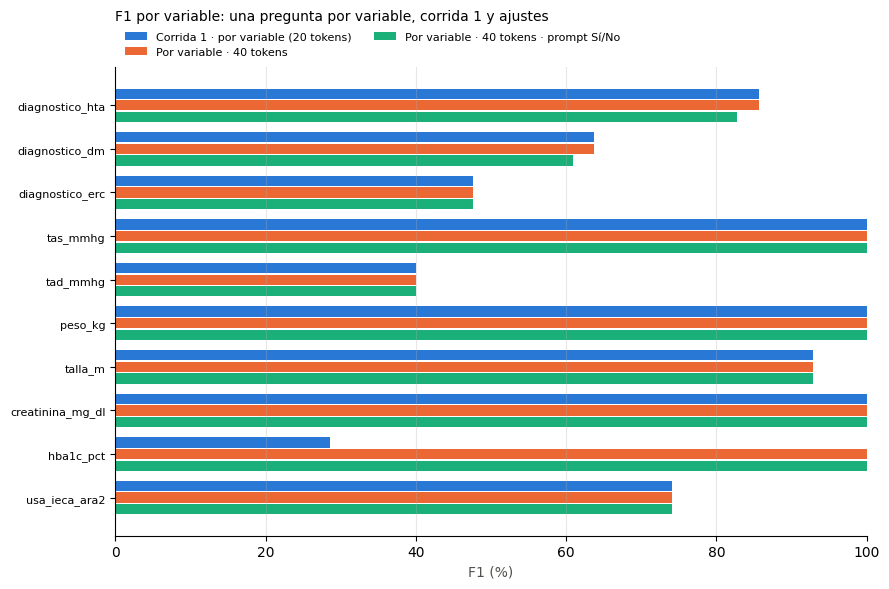

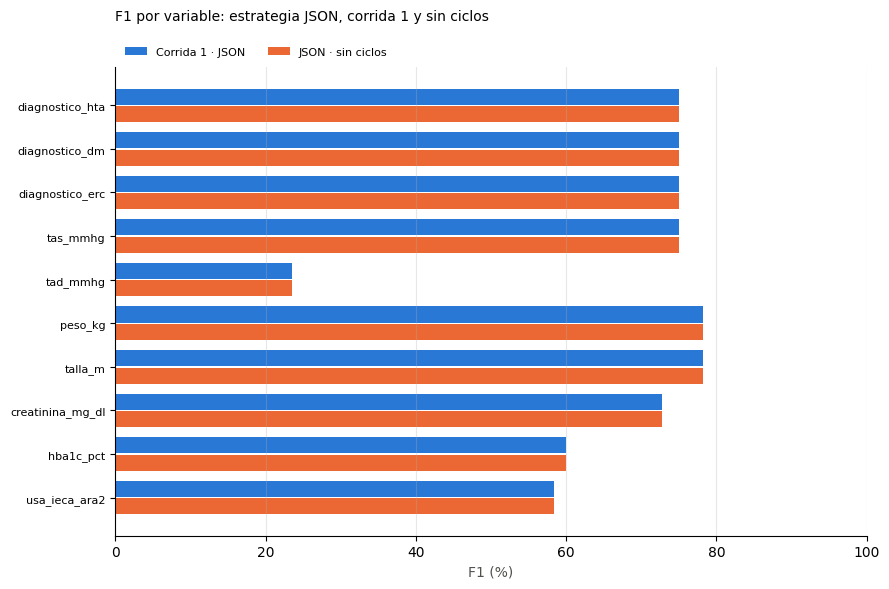

In [8]:
import matplotlib.pyplot as plt

from src.graficos import SERIES, TEXTO_SECUNDARIO
from src.metricas import precision_recall_f1

detalle1_lectura = detalle1.copy()
detalle1_lectura["valor"] = [None if v == "" else (v if t == "si_no" else float(v)) for v, t in zip(detalle1["valor"], detalle1["tipo"])]
detalle1_lectura["esperado"] = [None if v == "" else (v if t == "si_no" else float(v)) for v, t in zip(detalle1["esperado"], detalle1["tipo"])]


def f1_por_variable(detalle, estrategia):
    propias = detalle[detalle["estrategia"] == estrategia]
    return pd.Series({clave: precision_recall_f1(list(zip(propias[propias["variable"] == clave]["valor"],
                                                           propias[propias["variable"] == clave]["esperado"])))["F1"]
                      for clave in TIPOS})


f1 = pd.DataFrame({
    "Corrida 1 · por variable (20 tokens)": f1_por_variable(detalle1_lectura, "Una pregunta por variable"),
    "Por variable · 40 tokens": f1_por_variable(detalle2, "Por variable · 40 tokens"),
    "Por variable · 40 tokens · prompt Sí/No": f1_por_variable(detalle2, "Por variable · 40 tokens · prompt Sí/No"),
    "Corrida 1 · JSON": f1_por_variable(detalle1_lectura, "Un solo prompt con JSON"),
    "JSON · sin ciclos": f1_por_variable(detalle2, "JSON · sin ciclos"),
})
f1.to_csv("resultados/corrida2_f1_por_variable.csv")
display(f1.round(2))


def barras(series, titulo, archivo):
    variables = list(TIPOS)
    figura, eje = plt.subplots(figsize=(9, 6))
    alto = 0.8 / len(series)
    for k, nombre in enumerate(series):
        posiciones = [i + (k - (len(series) - 1) / 2) * alto for i in range(len(variables))]
        eje.barh(posiciones, f1[nombre].reindex(variables).values * 100, height=alto - 0.03, color=SERIES[k], label=nombre)
    eje.set_yticks(range(len(variables)), variables, fontsize=8)
    eje.invert_yaxis()
    eje.set_xlim(0, 100)
    eje.set_xlabel("F1 (%)", color=TEXTO_SECUNDARIO)
    eje.set_title(titulo, fontsize=10, loc="left", pad=34)
    eje.grid(axis="x", alpha=0.3)
    eje.spines[["top", "right"]].set_visible(False)
    eje.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8)
    figura.tight_layout()
    figura.savefig(f"resultados/{archivo}", dpi=150)
    plt.show()


barras(["Corrida 1 · por variable (20 tokens)", "Por variable · 40 tokens", "Por variable · 40 tokens · prompt Sí/No"],
       "F1 por variable: una pregunta por variable, corrida 1 y ajustes", "corrida2_f1_por_variable.png")
barras(["Corrida 1 · JSON", "JSON · sin ciclos"], "F1 por variable: estrategia JSON, corrida 1 y sin ciclos", "corrida2_f1_json.png")

## 8. Tiempo y memoria

In [9]:
display(corridas.groupby("estrategia", sort=False)["segundos"].describe()[["mean", "50%", "min", "max"]].round(1)
        .rename(columns={"mean": "media", "50%": "mediana", "min": "mínimo", "max": "máximo"}))
if torch.cuda.is_available():
    print(f"VRAM máxima durante la corrida 2: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

,media,mediana,mínimo,máximo
estrategia,,,,
Por variable · 40 tokens,24.5,24.6,20.2,29.1
Por variable · 40 tokens · prompt Sí/No,25.3,25.8,21.1,30.2
JSON · sin ciclos,11.3,10.1,7.0,20.2


VRAM máxima durante la corrida 2: 14.82 GB


## 9. Dónde se sigue equivocando

Casillas que no coinciden en la corrida 2 (respuesta recortada a 90 caracteres).

In [10]:
fallos = resultados[~resultados["correcto"]].copy()
fallos["respuesta"] = fallos["respuesta"].str.slice(0, 90)
pd.set_option("display.max_rows", 500)
display(fallos[["caso", "estrategia", "variable", "respuesta", "n_tokens", "valor", "esperado", "resultado"]])

,caso,estrategia,variable,respuesta,n_tokens,valor,esperado,resultado
2,caso_1.txt,Por variable · 40 tokens,diagnostico_erc,No registrado.,4,None,No,omitido
12,caso_1.txt,Por variable · 40 tokens · prompt Sí/No,diagnostico_erc,No registrado.,4,None,No,omitido
20,caso_1.txt,JSON · sin ciclos,diagnostico_hta,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,Sí,omitido
21,caso_1.txt,JSON · sin ciclos,diagnostico_dm,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,Sí,omitido
22,caso_1.txt,JSON · sin ciclos,diagnostico_erc,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,No,omitido
23,caso_1.txt,JSON · sin ciclos,tas_mmhg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,138,omitido
24,caso_1.txt,JSON · sin ciclos,tad_mmhg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,84,omitido
25,caso_1.txt,JSON · sin ciclos,peso_kg,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,76,omitido
26,caso_1.txt,JSON · sin ciclos,talla_m,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,1.68,omitido
27,caso_1.txt,JSON · sin ciclos,creatinina_mg_dl,"Sí, sí. Sí, no. Sí, sí. Sí, no. Sí. Sí, sí. Sí...",42,None,1.15,omitido


## 10. Descargar los resultados

In [11]:
archivos = ["corrida2_detalle.csv", "corrida2_tiempos.csv", "corrida2_resumen.csv", "ablacion.csv",
            "corrida2_f1_por_variable.csv", "corrida2_f1_por_variable.png", "corrida2_f1_json.png"]
if EN_COLAB:
    from google.colab import files
    for archivo in archivos:
        files.download(f"resultados/{archivo}")
else:
    print("Resultados en la carpeta resultados/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>